# Fold the Earth responses with a cosmic-ray spectrum

This Jupyter notebook continues the [processed Earth simulation](run-earth-simulation.md).
It is at `docs/tutorials/earth-spectrum-folding.ipynb`.
[View notebook](earth-spectrum-folding.ipynb) or download
{download}`earth-spectrum-folding.ipynb <earth-spectrum-folding.ipynb>`.

**Previous step:** [Run and inspect the Earth simulation](run-earth-simulation.md).

The simulation gives the average response to an incoming particle at each
energy. A cosmic-ray spectrum tells us how many particles arrive at those
energies. Multiplying the responses by the arrival rates and adding over
energy gives, for example, the number of ion pairs formed per second at each
altitude.

We'll use incoming protons to calculate atmospheric ionization and absorbed
dose in the water phantom. Set `run_dir` to your Earth run directory and run the cells in order.
The spectrum data come from a small online table; the plots use your own
simulation results.

The saved plots use the 1 km Earth model and the original ICRU water-sphere table from the preparation tutorial, with four completed proton chunks
(808 primaries) in `runs/earth-spectrum-original-phantoms`.

In [1]:
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import matplotlib.pyplot as plt
from atris_tools.psf import DETECTOR_ID, OUTER_RADIUS, PSF

run_dir = Path.cwd()  # Set this to your Earth run directory.

## 1. Look at one response table

Start with `protons.ioni`, written by `atris-postprocess`. Its rows describe
altitudes, and its response columns describe incoming proton energies:

| Column | Contents |
| --- | --- |
| 0 | Layer ID |
| 1 | Altitude in km |
| 2 onward | Ionizing energy deposition, in MeV cm$^{-3}$ per incoming proton |

`np.loadtxt` reads this into a two-dimensional array. Let's see the first three
rows and five columns. The slice `:3` means “up to row 3, excluding row 3”.

In [2]:
proton_table = np.loadtxt(run_dir / "protons.ioni")
proton_table[:3, :5]

array([[ 1.  , -0.02,  0.  ,  0.  ,  0.  ],
       [ 2.  ,  0.  ,  0.  ,  0.  ,  0.  ],
       [ 3.  ,  1.  ,  0.  ,  0.  ,  0.  ]])

Keep the atmospheric rows, leaving out the interior, crust, and outer stopping
shell. The Earth PSF lists the atmosphere between its first two and last rows.

`proton_response` will have one row per atmospheric layer and one column per
energy bin. `protons.bins` contains the **edges** of those bins, in MeV. Divide
by 1000 to work in GeV.

In [3]:
planet = PSF.read(run_dir / "simulation.psf")
atmospheric_ids = planet.layers[2:-1, DETECTOR_ID]
atmosphere = np.isin(proton_table[:, 0], atmospheric_ids)

altitude = proton_table[atmosphere, 1]
proton_response = proton_table[atmosphere, 2:]
proton_edges = np.loadtxt(run_dir / "protons.bins") / 1000

print("Rows (altitudes), columns (energy bins):", proton_response.shape)

Rows (altitudes), columns (energy bins): (101, 120)


Each energy bin needs some simulated primaries before we can calculate a total.
An unsampled bin usually appears as `NaN`: its response is unknown, rather than
zero. If the check below fails, gather and post-process more completed chunks.
You don't need to finish the whole run.

In [4]:
assert np.isfinite(proton_response).all(), "Some proton responses are still undefined."

## 2. Choose the incoming spectrum

We'll use the proton spectrum of
[Boschini et al. (2017)](https://doi.org/10.3847/1538-4357/aa6e4f), available as
[Table 6 at CDS](https://cdsarc.cds.unistra.fr/viz-bin/ReadMe/J/ApJ/840/115?format=html).
It describes cosmic rays outside the heliosphere. We apply a solar-modulation
model to estimate the spectrum reaching Earth.

Read the published table. Its columns contain rigidity in GV and differential
intensity per m², second, steradian, and GV.

In [5]:
url = "https://cdsarc.cds.unistra.fr/ftp/J/ApJ/840/115/table6.dat"
with urlopen(url, timeout=30) as stream:
    proton_spectrum = np.loadtxt(stream)

We need intensity as a function of proton kinetic energy, $T$, in GeV.

The function below converts the table's rigidity coordinate to energy and
applies solar modulation. Its result is in m$^{-2}$ s$^{-1}$ sr$^{-1}$ GeV$^{-1}$.
`np.interp` interpolates between table values; logarithms make this suitable for
a spectrum spanning many orders of magnitude.

The modulation potential $\phi$ controls how strongly the solar wind suppresses
low-energy cosmic rays. Start with $\phi=0.5$ GV; later we will increase it
to see how the radiation changes. The equations are given
[at the end](#the-spectrum-conversion).

In [6]:
def spectrum(T, phi=0.5):
    m = 0.938272                                # proton rest energy, GeV
    shifted = T + phi
    rigidity = np.sqrt(shifted * (shifted + 2 * m))
    log_intensity = np.interp(np.log(rigidity), np.log(proton_spectrum[:, 0]),
                              np.log(proton_spectrum[:, 1]), left=np.nan, right=np.nan)
    dP_dT = (shifted + m) / rigidity
    modulation = T * (T + 2 * m) / (shifted * (shifted + 2 * m))
    return np.exp(log_intensity) * dP_dT * modulation

Plot the proton spectrum before using it. `geomspace` gives evenly spaced
points on a logarithmic axis; `loglog` makes both plot axes logarithmic.

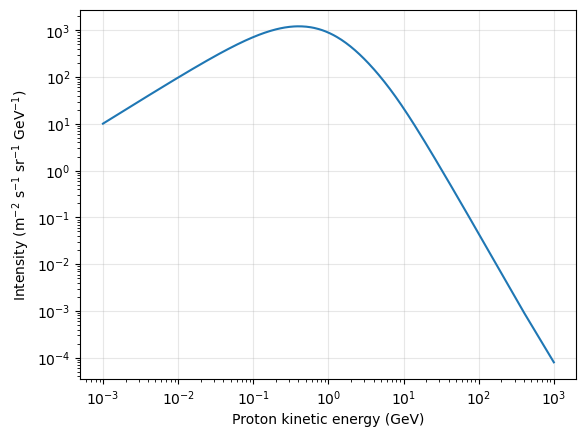

In [7]:
energy = np.geomspace(proton_edges[0], proton_edges[-1], 400)

fig, ax = plt.subplots()
ax.loglog(energy, spectrum(energy))
ax.set_xlabel("Proton kinetic energy (GeV)")
ax.set_ylabel(r"Intensity (m$^{-2}$ s$^{-1}$ sr$^{-1}$ GeV$^{-1}$)")
ax.grid(alpha=0.3)
plt.show()

## 3. Turn intensity into arriving particles

An energy bin has a finite width. Integrate the spectrum across that width to
find its intensity, rather than using the intensity at a single point.
Here we split each bin into 32 small intervals and add their trapezoidal areas:

$$
\int J(T)\,dT\simeq\sum_i\frac{J_i+J_{i+1}}{2}(T_{i+1}-T_i).
$$

The array `samples` has one row per original bin. `np.diff` gives the small
interval widths, and `sum(axis=1)` adds along each row.

In [8]:
samples = np.geomspace(proton_edges[:-1], proton_edges[1:], 33, axis=1)
intensity = spectrum(samples)
mean_intensity = (intensity[:, :-1] + intensity[:, 1:]) / 2
bin_intensity = np.sum(mean_intensity * np.diff(samples), axis=1)

The standard Earth source launches particles from a sphere one metre above the
atmosphere, with cosine-distributed inward directions. For isotropic intensity,
the sphere's area contributes $4\pi r_s^2$ and the angular integral contributes
$\pi$. Thus

$$
\dot N_b=4\pi^2r_s^2\int_{T_b}^{T_{b+1}}J(T)\,dT.
$$

Use metres for $r_s$, matching the spectrum's square metres. This normalization
assumes the unchanged source from the Earth example and no geomagnetic cutoff.

In [9]:
source_radius = (planet.layers[-2, OUTER_RADIUS] + 0.001) * 1000  # km to m, including the 1 m offset
source_factor = 4 * np.pi**2 * source_radius**2
proton_rate = source_factor * bin_intensity    # arriving protons/s in each bin

## 4. Fold the response and plot ionization

Now multiply each response column by the number of arriving protons in that
energy bin. NumPy applies the one-dimensional `proton_rate` array across every
altitude row. This is called **broadcasting**.

Adding across the columns gives energy deposition per cm³ per second.
Convert MeV to eV, then divide by $W=35$ eV per ion pair for air, following
[Banjac et al. (2019)](https://doi.org/10.1029/2019JA026622):

$$
q(h)=\frac{10^6}{35}\sum_b R_{h,b}\,\dot N_b.
$$

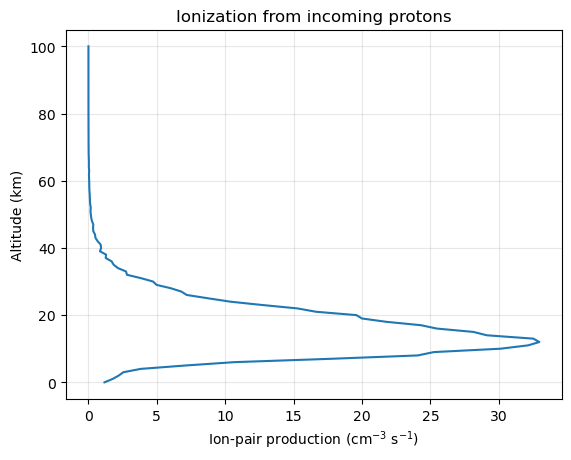

In [10]:
proton_contributions = proton_response * proton_rate
proton_ionization = proton_contributions.sum(axis=1) * 1e6 / 35

fig, ax = plt.subplots()
ax.plot(proton_ionization, altitude)
ax.set_xlabel(r"Ion-pair production (cm$^{-3}$ s$^{-1}$)")
ax.set_ylabel("Altitude (km)")
ax.set_title("Ionization from incoming protons")
ax.grid(alpha=0.3)
plt.show()

This is the contribution from incoming protons **and all their secondaries**.
The values are layer averages, shown at the lower-boundary altitudes in the
response table.

Look at which proton energies contribute at 12 km.
`argmin` finds the row whose altitude is closest to that value. Keeping the
columns separate shows what went into the sum above.

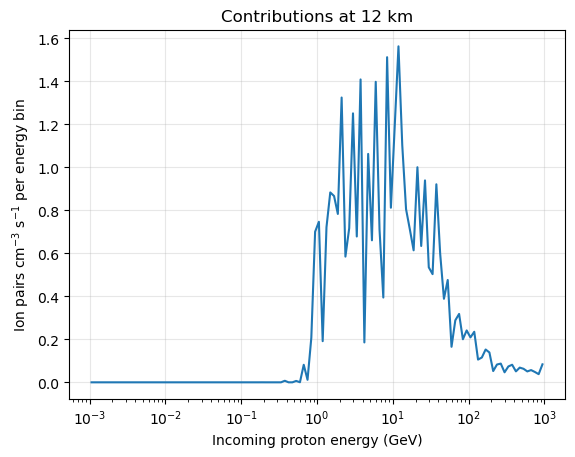

In [11]:
row = np.abs(altitude - 12).argmin()
energy_centres = np.sqrt(proton_edges[:-1] * proton_edges[1:])
contribution = proton_contributions[row] * 1e6 / 35

fig, ax = plt.subplots()
ax.semilogx(energy_centres, contribution)
ax.set_xlabel("Incoming proton energy (GeV)")
ax.set_ylabel(r"Ion pairs cm$^{-3}$ s$^{-1}$ per energy bin")
ax.set_title(f"Contributions at {altitude[row]:g} km")
ax.grid(alpha=0.3)
plt.show()

## 5. Calculate absorbed dose in the water phantom

The Earth example selects the ICRU water sphere as phantom 1. Its `.dose1` table
contains deposited energy per unit phantom mass per incoming primary. We fold
it with the **same proton arrival rates** used above.

Post-processing has already applied the phantom mass and area. For this
energy-fraction response table, the folded values are in eV g$^{-1}$ s$^{-1}$.
Use $1\ \mathrm{eV/g}=1.602176634\times10^{-16}\ \mathrm{Gy}$, then multiply by
3600 for hours and $10^6$ for microgray.

The rows match the ionization table, so we can reuse `atmosphere` to select them.

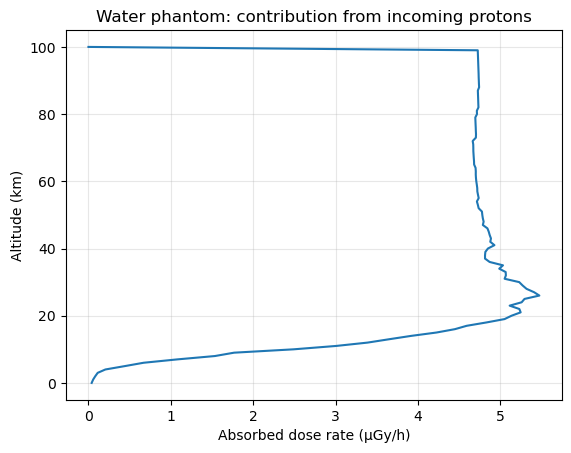

In [12]:
dose_table = np.loadtxt(run_dir / "protons.dose1")
dose_response = dose_table[atmosphere, 2:]

dose_rate = (dose_response * proton_rate).sum(axis=1)
dose_microgray_per_hour = dose_rate * 1.602176634e-16 * 3600 * 1e6

fig, ax = plt.subplots()
ax.plot(dose_microgray_per_hour, altitude)
ax.set_xlabel("Absorbed dose rate (µGy/h)")
ax.set_ylabel("Altitude (km)")
ax.set_title("Water phantom: contribution from incoming protons")
ax.grid(alpha=0.3)
plt.show()

The other response tables use the same multiplication and sum.
For `.equi1`, the result includes [AtRIS's radiation weights](../reference/outputs.md#radiation-weighting-as-implemented)
and the corresponding conversion gives µSv/h. These weights have
[known discrepancies from ICRP 103](../known-bugs.md#possible-radiation-weighting-bug).
For a phantom with a calculated counting-efficiency table, folding `.ratesN`
gives counts/s without the dose conversion. The ID `N` selects the phantom
listed in `phantoms.txt`. The example's cell phantom has only a placeholder
counting table, so its `.rates0` is not a detector count-rate prediction.

Alphas follow the same process with their own response tables and incident
spectrum. Their bin edges are total energy per nucleus: divide by $1000\times4$
to match a spectrum expressed per GeV/nucleon. Fold each species separately,
then add its rates. The plots here show only the proton contribution.

## 6. Change the spectrum, keep the simulation

What happens if solar modulation is stronger? Set $\phi=1$ GV and recalculate
the arrival rates. The response matrix stays the same.

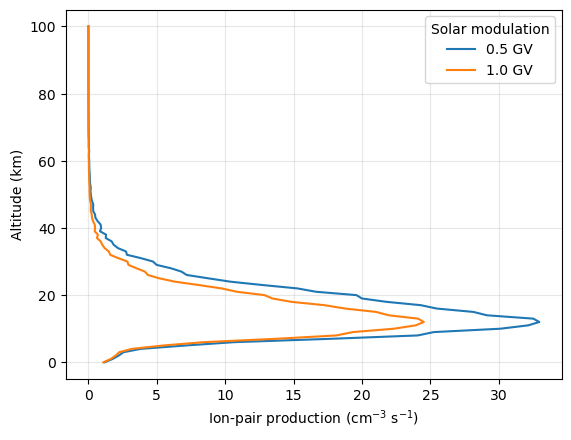

In [13]:
intensity_strong = spectrum(samples, phi=1.0)
mean_intensity_strong = (intensity_strong[:, :-1] + intensity_strong[:, 1:]) / 2
proton_rate_strong = source_factor * np.sum(mean_intensity_strong * np.diff(samples), axis=1)
ionization_strong = (proton_response * proton_rate_strong).sum(axis=1) * 1e6 / 35

fig, ax = plt.subplots()
ax.plot(proton_ionization, altitude, label="0.5 GV")
ax.plot(ionization_strong, altitude, label="1.0 GV")
ax.set_xlabel(r"Ion-pair production (cm$^{-3}$ s$^{-1}$)")
ax.set_ylabel("Altitude (km)")
ax.legend(title="Solar modulation")
ax.grid(alpha=0.3)
plt.show()

The stronger modulation removes more low-energy primaries. Compare the change
with the energy-contribution plot: which parts of the incoming spectrum matter
most at your chosen altitude?

These results cover the proton energies in the simulation, with no geomagnetic
filtering. More completed chunks improve the statistics; gather and post-process
them, then rerun the notebook. Folding also approximates the response as constant
within each energy bin. See [normalization and uncertainty](../background/normalization-and-uncertainty.md)
for that approximation and the distinction between sampling noise and model
uncertainty.

### The spectrum conversion

For a proton with rest energy $m$, rigidity and kinetic energy are related by

$$
P(T)=\sqrt{T(T+2m)},\qquad
\frac{dP}{dT}=\frac{T+m}{\sqrt{T(T+2m)}}.
$$

Changing the spectrum's coordinate preserves particle numbers:
$J_T\,dT=J_P\,dP$. Hence `spectrum` multiplies the tabulated intensity by
`dP_dT`. Energies are in GeV and rigidity is in GV.

The force-field approximation for protons then gives

$$
J(T,\phi)=J_{\rm LIS}(T+\phi)
\frac{T(T+2m)}{(T+\phi)(T+\phi+2m)}.
$$

Here $J_{\rm LIS}$ is the interstellar intensity **after** converting to the
energy coordinate, and the numerical value of $\phi$ in GV gives the proton
energy shift in GeV. See [Koldobskiy et al. (2019), Section 4](https://doi.org/10.1029/2018JA026340)
for the approximation. Interpolation outside the published table returns `NaN`,
rather than extrapolating the spectrum.

**Previous step:** [Run and inspect the Earth simulation](run-earth-simulation.md).